In [2]:
import matplotlib.pyplot as plt
import numpy as np
import control
from numpy import sin, cos, tan, pi
from control import TransferFunction as TF

In [3]:
import os

In [14]:
import textwrap

In [15]:
plt.rcParams['font.size'] = 14

In [16]:
try:
    import pylab_util as PU
    amIdrkrauss = True
    from krauss_misc import rwkos
except:
    amIdrkrauss = False

In [17]:
amIdrkrauss

True

In [18]:
if amIdrkrauss:
    def save_eps(pngname):
        fno, ext = os.path.splitext(pngname)
        eps_name = fno + '.eps'
        folder = 'figs'
        rwkos.make_dir(folder)
        eps_path = os.path.join(folder, eps_name)
        PU.mysave(eps_path)

## Calculate the Step Response

In [19]:
# 1. Define second-order system parameters: G(s) = wn^2 / (s^2 + 2*zeta*wn*s + wn^2)
wn = 2.0  # Natural frequency (rad/s)
zeta = 0.25  # Damping ratio (underdamped: 0 < zeta < 1)
tol = 0.02  # Settling time tolerance band (2%)

G = control.TransferFunction([wn**2], [1, 2 * zeta * wn, wn**2])
t = np.arange(0,10,0.01)
t, y = control.step_response(G, T=t)

## Annotate

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


cmd=epstopdf figs/settling_time.eps
pdfcrop figs/settling_time.pdf figs/settling_time.pdf
PDFCROP 1.42, 2023/04/15 - Copyright (c) 2002-2023 by Heiko Oberdiek, Oberdiek Package Support Group.
==> 1 page written on `figs/settling_time.pdf'.


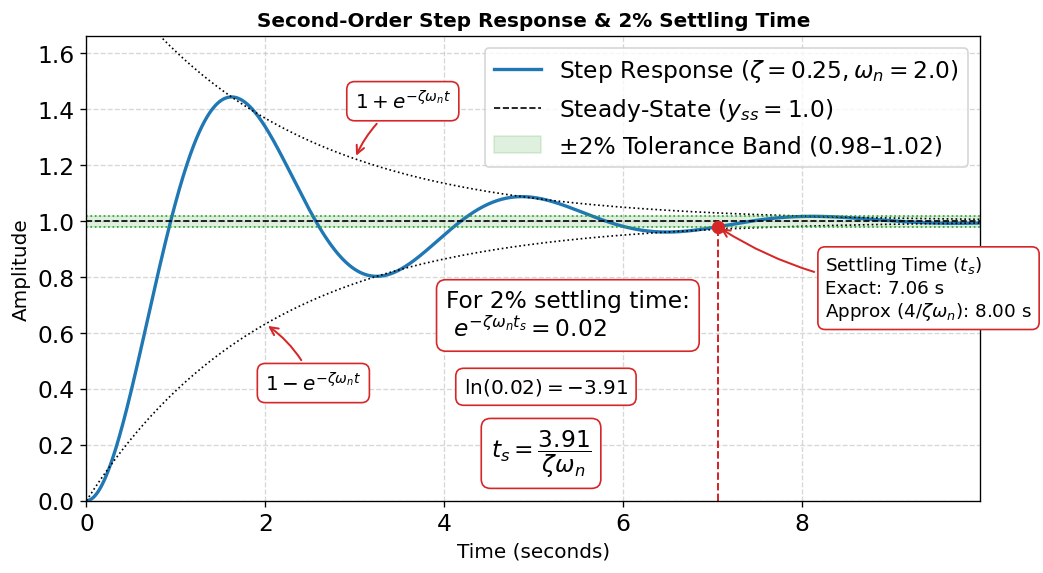

In [20]:

# 2. Calculate exact settling time (last point outside the +/- tol band)
y_ss = 1.0  # Steady-state value for unit step
upper_bound = y_ss * (1 + tol)
lower_bound = y_ss * (1 - tol)

upper_env = 1+np.exp(-zeta*wn*t)
lower_env = 1-np.exp(-zeta*wn*t)

outside_band = np.where((y > upper_bound) | (y < lower_bound))[0]
ts_idx = outside_band[-1] + 1
ts = t[ts_idx]
y_ts = y[ts_idx]

# Theoretical approximation for comparison: ts ≈ 4 / (zeta * wn)
ts_approx = 4 / (zeta * wn)

# 3. Create the annotated plot
fig, ax = plt.subplots(figsize=(9, 5), dpi=120)

# Main step response curve
ax.plot(
    t, y, color="#1f77b4", linewidth=2, label=rf"Step Response ($\zeta={zeta}, \omega_n={wn}$)"
)

env_kwargs = {"color":"k", "linestyle":":", "linewidth":1}
ax.plot(t, upper_env, **env_kwargs)
ax.plot(t, lower_env, **env_kwargs)

# Steady-state line and tolerance band shading
ax.axhline(y_ss, color="black", linestyle="--", linewidth=1, label="Steady-State ($y_{ss} = 1.0$)")
ax.axhspan(
    lower_bound,
    upper_bound,
    color="#2ca02c",
    alpha=0.15,
    label=f"±{int(tol*100)}% Tolerance Band ({lower_bound:.2f}–{upper_bound:.2f})",
)
ax.axhline(upper_bound, color="#2ca02c", linestyle=":", linewidth=1)
ax.axhline(lower_bound, color="#2ca02c", linestyle=":", linewidth=1)

# Vertical drop line and marker at settling time
ax.vlines(ts, 0, y_ts, color="#d62728", linestyle="--", linewidth=1.2)
ax.plot(ts, y_ts, "o", color="#d62728", markersize=7, zorder=5)

# Annotation callout with arrow
ax.annotate(
    f"Settling Time ($t_s$)\nExact: {ts:.2f} s\nApprox ($4/\\zeta\\omega_n$): {ts_approx:.2f} s",
    xy=(ts, y_ts),
    xytext=(ts + 1.2, y_ts - 0.32),
    fontsize=11,
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="#d62728", lw=1),
    arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=-0.15", color="#d62728", lw=1.2),
)

def settling_textbox(x, y, mytext, fs=12):
    ax.annotate(
        mytext, 
        xy=(x, y),
        xytext=(1, 1),
        textcoords="offset points",
        fontsize=fs,
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="#d62728", lw=1),
        arrowprops=None, \
    )

blurb1 = "For 2% settling time:\n $e^{-\\zeta \\omega_n t_s} = 0.02$"
blurb2 =  "$t_s = \\dfrac{3.91}{\\zeta \\omega_n}$"
settling_textbox(4, 0.58, blurb1, fs=14)
settling_textbox(4.5, 0.15, blurb2, fs=14)
settling_textbox(4.2,0.38,"$\\ln(0.02) = -3.91$")
# Formatting
ax.set_title(
    f"Second-Order Step Response & {int(tol*100)}% Settling Time", fontsize=12, fontweight="bold"
)

## upper envelope label
t_uenv = 3
y_uenv = 1+np.exp(-zeta*wn*t_uenv)
t_lenv = 2
y_lenv = 1-np.exp(-zeta*wn*t_lenv)

ax.annotate(
    "$1+e^{-\\zeta \\omega_n t}$",
    xy=(t_uenv, y_uenv),
    xytext=(0, 30),
    textcoords="offset points",
    fontsize=12,
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="#d62728", lw=1),
    arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=0.15", color="#d62728", lw=1.2),
)

ax.annotate(
    "$1-e^{-\\zeta \\omega_n t}$",
    xy=(t_lenv, y_lenv),
    xytext=(0, -40),
    textcoords="offset points",
    fontsize=12,
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="#d62728", lw=1),
    arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=0.15", color="#d62728", lw=1.2),
)


ax.set_xlabel("Time (seconds)", fontsize=12)
ax.set_ylabel("Amplitude", fontsize=12)
ax.set_xlim(0, t[-1])
ax.set_ylim(0, max(y) * 1.15)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="upper right", frameon=True)

plt.tight_layout()

png_name = "settling_time.png"
resave = 1
if resave:
    plt.savefig(png_name)
    if amIdrkrauss:
        save_eps(png_name)

In [21]:
np.log(0.02)

np.float64(-3.912023005428146)

## My Annotations

### Peak Time and Overshoot

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


cmd=epstopdf figs/overshoot.eps
pdfcrop figs/overshoot.pdf figs/overshoot.pdf
PDFCROP 1.42, 2023/04/15 - Copyright (c) 2002-2023 by Heiko Oberdiek, Oberdiek Package Support Group.
==> 1 page written on `figs/overshoot.pdf'.


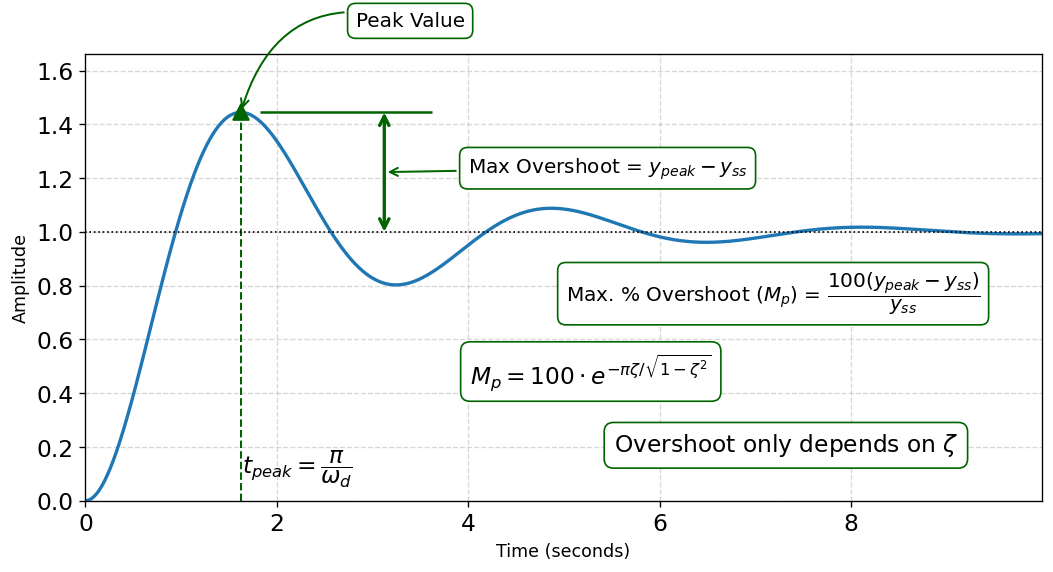

In [12]:
fig, ax = plt.subplots(figsize=(9, 5), dpi=120)

# Main step response curve
ax.plot(
    t, y, color="#1f77b4", linewidth=2, label=rf"Step Response ($\zeta={zeta}, \omega_n={wn}$)"
)

#ax.axhline(upper_bound, color="k", linestyle=":", linewidth=1)
#ax.axhline(lower_bound, color="k", linestyle=":", linewidth=1)

t_s = 3.91/(zeta*wn)
wd = wn*np.sqrt(1-zeta**2)
t_p = pi/wd
index_p = np.where(t>=t_p)[0][0]
max_os = y[index_p]
peak_color = "darkGreen"
ax.plot(t[index_p],max_os,'^', color=peak_color, markersize=10)

ax.annotate(
    "Peak Value",
    xy=(t_p, max_os),
    xytext=(t_p + 1.2, max_os + 0.32),
    fontsize=12,
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor=peak_color, lw=1),
    arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=0.5", color=peak_color, lw=1.2),
)
ax.vlines(t_p, 0, max_os, color=peak_color, linestyle="--", linewidth=1.2)
ax.text(t_p+0.01, 0.1, "$t_{peak} = \\dfrac{\\pi}{\\omega_d}$")

# dimension lines
#ax.plot([t_p+0.2,t_p+2],[max_os, max_os], color=peak_color, linestyle="-", linewidth=1.2)
ax.hlines(max_os, t_p+0.2, t_p+2, color=peak_color)
v_dim_x = t_p+1.5
#ax.vlines(v_dim_x, y_ss, max_os, color=peak_color)

ax.axhline(y_ss,color="k", linestyle=":", linewidth=1)

ax.annotate(
    "", 
    xy=(v_dim_x, max_os),         # End point
    xytext=(v_dim_x, y_ss),     # Start point
    arrowprops=dict(
        arrowstyle="<->",  # Double-headed arrow
        color=peak_color,
        lw=2,
        shrinkA=0,         # Prevents shortening at the start point
        shrinkB=0          # Prevents shortening at the end point
    )
)

mid_dim = (max_os+y_ss)/2
ax.annotate(
    "Max Overshoot = $y_{peak} - y_{ss}$",
    xy=(v_dim_x, mid_dim),
    xytext=(50, 10),
    textcoords="offset points",
    fontsize=12,
    va="top",
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor=peak_color, lw=1),
    arrowprops=dict(arrowstyle="->", color=peak_color, lw=1.2),
)

#ax.text(3,0.6,"Max. % Overshoot ($M_p$) = $\\dfrac{100(y_{peak} -y_{ss})}{y_{ss}}$", \
#       fontsize=11.5)
#ax.text(4,0.3, "$M_p = 100 \\cdot e^{-\\pi \\zeta/\\sqrt{1-\\zeta^2}}$")
#ax.text(5,0.15, "Overshoot only depends on $\\zeta$")

def overshoot_textbox(x,y,mytext, fs=12):
    ax.annotate(
        mytext,
        xy=(x,y),
        xytext=(1, 1),
        textcoords="offset points",
        fontsize=fs,
        va="top",
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor=peak_color, lw=1),
        arrowprops=None, \
    )

overshoot_textbox(5,0.85, \
                  "Max. % Overshoot ($M_p$) = $\\dfrac{100(y_{peak} -y_{ss})}{y_{ss}}$")
overshoot_textbox(4,0.55, "$M_p = 100 \\cdot e^{-\\pi \\zeta/\\sqrt{1-\\zeta^2}}$", fs=14)
overshoot_textbox(5.5,0.25, "Overshoot only depends on $\\zeta$", fs=14)
ax.set_xlabel("Time (seconds)", fontsize=10.5)
ax.set_ylabel("Amplitude", fontsize=10.5)
ax.set_xlim(0, t[-1])
ax.set_ylim(0, max(y) * 1.15)
ax.grid(True, linestyle="--", alpha=0.5)
#ax.legend(loc="upper right", frameon=True)
plt.tight_layout()
png_name = "overshoot.png"
resave = 1
if resave:
    plt.savefig(png_name)
    if amIdrkrauss:
        save_eps(png_name)

## Rise Time

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


cmd=epstopdf figs/rise_time.eps
pdfcrop figs/rise_time.pdf figs/rise_time.pdf
PDFCROP 1.42, 2023/04/15 - Copyright (c) 2002-2023 by Heiko Oberdiek, Oberdiek Package Support Group.
==> 1 page written on `figs/rise_time.pdf'.


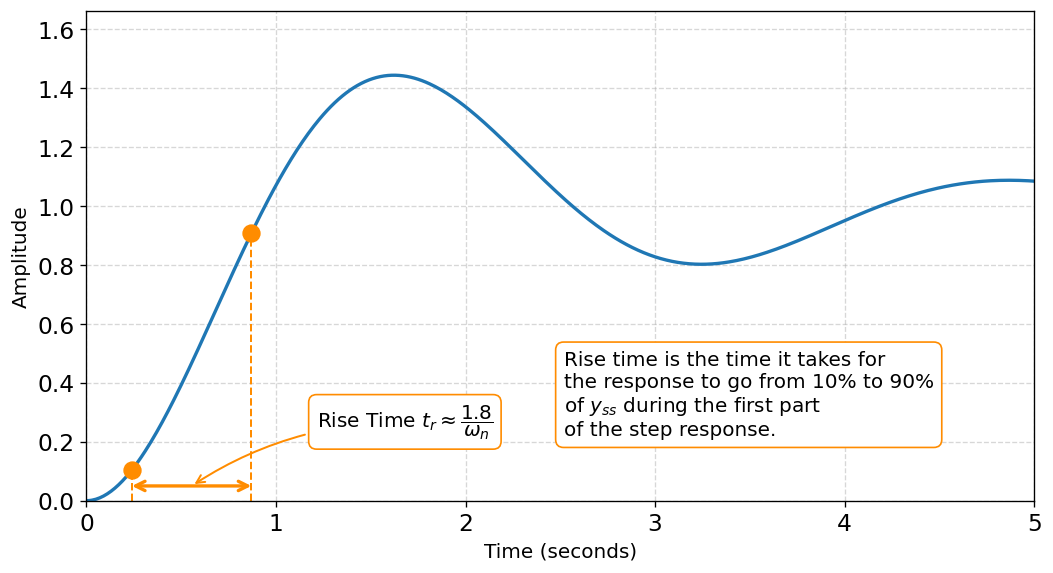

In [13]:
fig, ax = plt.subplots(figsize=(9, 5), dpi=120)

# Main step response curve
ax.plot(
    t, y, color="#1f77b4", linewidth=2, label=rf"Step Response ($\zeta={zeta}, \omega_n={wn}$)"
)

index_r1 = np.where(y>=0.1*y_ss)[0][0]
index_r2 = np.where(y>=0.9*y_ss)[0][0]
t_r1 = t[index_r1]
t_r2 = t[index_r2]
y_r1 = y[index_r1]
y_r2 = y[index_r2]

rise_color = 'darkOrange'
ax.plot([t_r1,t_r2],[y_r1,y_r2], 'o', color=rise_color, markersize=10)

ax.vlines(t_r1, 0, y_r1, color=rise_color, linestyle="--", linewidth=1.2)
ax.vlines(t_r2, 0, y_r2, color=rise_color, linestyle="--", linewidth=1.2)
ax.annotate(
    "", 
    xy=(t_r1, 0.05),         # End point
    xytext=(t_r2, 0.05),     # Start point
    arrowprops=dict(
        arrowstyle="<->",  # Double-headed arrow
        color=rise_color,
        lw=2,
        shrinkA=0,         # Prevents shortening at the start point
        shrinkB=0          # Prevents shortening at the end point
    )
)

mid_dim = (t_r2+t_r1)/2
ax.annotate(
    "Rise Time $t_r \\approx \\dfrac{1.8}{\\omega_n}$",
    xy=(mid_dim, 0.05),
    xytext=(75, 50),
    textcoords="offset points",
    fontsize=12,
    va="top",
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor=rise_color, lw=1),
    arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=0.15", color=rise_color, lw=1.2),
)

long_explain = "Rise time is the time it takes for the response to go from 10% to 90% of $y_{ss}$ " + \
                "during the first part of the step response."

wrapped_text = textwrap.fill(long_explain, width=35)

#ax.text(2.5,0.3, wrapped_text)
ax.annotate(
    wrapped_text,
    xy=(2.5, 0.5),
    xytext=(2, 2),
    textcoords="offset points",
    fontsize=12,
    va="top",
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor=rise_color, lw=1),
    arrowprops=None, \
)

ax.set_xlim(0, 5)
ax.set_ylim(0, max(y) * 1.15)
ax.grid(True, linestyle="--", alpha=0.5)
#ax.legend(loc="upper right", frameon=True)
ax.set_xlabel("Time (seconds)", fontsize=12)
ax.set_ylabel("Amplitude", fontsize=12)
plt.tight_layout()
png_name = "rise_time.png"
plt.savefig(png_name)
if amIdrkrauss:
    save_eps(png_name)